# **Clase 1. Carga y Limpieza de Datos**

## **1.  Definición del problema**

Se dispone de un dataset con información sociodemográfica de individuos (edad, ingreso, nivel educativo, profesión, entre otros), el cual presenta múltiples problemas de calidad como:

+ Datos faltantes
+ Registros duplicados
+ Inconsistencias en variables categóricas
+ Valores atípicos (outliers)
+ Datos erróneos (por ejemplo, ingresos negativos o edades irreales)


El problema consiste en:

Preparar y transformar el dataset para que sea apto para el entrenamiento de modelos de machine learning que apoyen la toma de decisiones.

## **2. Objetivo general**

Desarrollar un proceso completo de limpieza, transformación y preparación de datos que permita construir un dataset confiable y adecuado para aplicar técnicas de aprendizaje automático.

## **3. Objetivos específicos**

### **3.1 Identificar problemas de calidad de datos**

+ Detectar valores faltantes, duplicados e inconsistencias.

### **3.2 Realizar limpieza de datos**

+ Tratar valores nulos.
+ Eliminar o corregir registros erróneos.
+ Gestionar datos atípicos.

### **3.3 Estandarizar variables**

+ Unificar formatos de texto (mayúsculas/minúsculas).
+ Normalizar categorías (género, ciudad, estado civil).

### **3.4 Transformar variables**

+ Codificar variables categóricas (One-Hot, Ordinal).
+ Escalar variables numéricas.



### **3.5 Exportar datos**

##  Fase I. Carga y exploración inicial de datos

#1. Cargar los datos desde Google Drive a Google Colab.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Código para reiniciar el entorno de ejecución de manera automática
import os
os.kill(os.getpid(), 9)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#CARGAR LOS DATOS

In [ ]:
import pandas as pd
file_path='/content/drive/MyDrive/Ciencia de Datos IA/consumos_uptc.csv'

#2. Identificar dimensiones del conjunto de datos

In [ ]:
df=pd.read_csv(file_path)

In [ ]:
df.columns

Index(['reading_id', 'timestamp', 'sede', 'sede_id', 'energia_total_kwh',
       'energia_comedor_kwh', 'energia_salones_kwh',
       'energia_laboratorios_kwh', 'energia_auditorios_kwh',
       'energia_oficinas_kwh', 'potencia_total_kw', 'agua_litros',
       'temperatura_exterior_c', 'ocupacion_pct', 'hora', 'dia_semana',
       'dia_nombre', 'mes', 'trimestre', 'año', 'periodo_academico',
       'es_fin_semana', 'es_festivo', 'es_semana_parciales',
       'es_semana_finales', 'co2_kg'],
      dtype='object')

In [ ]:
df.shape

(275387, 26)

> El archivo tiene 275387 filas y 26 columnas


#3. Analizar variables y tipos de datos

In [ ]:
display(df.head())

,reading_id,timestamp,sede,sede_id,energia_total_kwh,energia_comedor_kwh,energia_salones_kwh,energia_laboratorios_kwh,energia_auditorios_kwh,energia_oficinas_kwh,...,dia_nombre,mes,trimestre,año,periodo_academico,es_fin_semana,es_festivo,es_semana_parciales,es_semana_finales,co2_kg
0,1,2018-01-01 00:00:00,Chiquinquirá,UPTC_CHI,0.928,0.0452,0.1497,0.4334,0.0386,0.2613,...,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.1877
1,2,2018-01-01 00:00:00,Duitama,UPTC_DUI,2.592,0.1129,0.2007,1.7993,0.0573,0.4217,...,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.4490
2,3,2018-01-01 00:00:00,Sogamoso,UPTC_SOG,2.841,0.1395,0.2388,1.9638,NaN,0.4443,...,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.6048
3,4,2018-01-01 00:00:00,Tunja,UPTC_TUN,1.505,0.0892,0.1091,0.9672,0.0364,0.3031,...,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.2872
4,5,2018-01-01 01:00:00,Chiquinquirá,UPTC_CHI,0.917,0.0479,0.1432,0.4071,0.0418,0.2766,...,Lunes,1,1,2018,vacaciones_fin,False,True,False,False,0.1599


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 275387 entries, 0 to 275386
Data columns (total 26 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   reading_id                275387 non-null  int64  
 1   timestamp                 275387 non-null  object 
 2   sede                      275387 non-null  object 
 3   sede_id                   275387 non-null  object 
 4   energia_total_kwh         275387 non-null  float64
 5   energia_comedor_kwh       267133 non-null  float64
 6   energia_salones_kwh       275387 non-null  float64
 7   energia_laboratorios_kwh  275387 non-null  float64
 8   energia_auditorios_kwh    261769 non-null  float64
 9   energia_oficinas_kwh      275387 non-null  float64
 10  potencia_total_kw         275387 non-null  float64
 11  agua_litros               264405 non-null  float64
 12  temperatura_exterior_c    259002 non-null  float64
 13  ocupacion_pct             242621 non-null  f

> Tu dataset registra 275,387 mediciones en 26 variables sobre el consumo energético, hídrico y ambiental de un campus universitario, agrupadas en identificadores de sede, consumo eléctrico desglosado por 5 áreas físicas, indicadores ambientales/operativos (agua_litros, temperatura_exterior_c, ocupacion_pct, co2_kg), marcas de tiempo y calendario académico. El 77% de las columnas están completas, pero 6 variables tienen entre 3% y 11.9% de valores nulos (siendo ocupacion_pct la más afectada), por lo que la prioridad técnica es convertir timestamp a formato fecha (datetime64) e imputar los datos faltantes agrupando por sede y hora.

#4. Explorar valores únicos por sede

In [ ]:
df['sede'].value_counts()

,count
sede,
Duitama,68862
Chiquinquirá,68859
Tunja,68837
Sogamoso,68829


> Las 275,387 mediciones están repartidas de forma casi idéntica (~25% o ~68,847 registros por sede) entre las cuatro seccionales principales de la UPTC en Boyacá (Tunja, Duitama, Sogamoso y Chiquinquirá), con una diferencia máxima de apenas 33 registros entre la sede con más datos y la de menos. Esto confirma que se trata de un panel de datos balanceado con la misma frecuencia de muestreo y ventana temporal en los cuatro campus, lo que evita sesgos de representación al comparar consumos entre sedes y exige que cualquier imputación de nulos o entrenamiento de modelos se haga segmentando o agrupando por sede.

#5. Obtener estadísticas descriptivas
#6.Detectar posibles inconsistencias

In [ ]:
df.describe()

,reading_id,energia_total_kwh,energia_comedor_kwh,energia_salones_kwh,energia_laboratorios_kwh,energia_auditorios_kwh,energia_oficinas_kwh,potencia_total_kw,agua_litros,temperatura_exterior_c,ocupacion_pct,hora,dia_semana,mes,trimestre,año,co2_kg
count,275387.000000,275387.000000,267133.000000,275387.000000,275387.000000,261769.000000,275387.000000,275387.000000,264405.000000,259002.000000,242621.000000,275387.000000,275387.000000,275387.000000,275387.000000,275387.000000,261591.000000
mean,137694.000000,5.079227,0.295954,0.975189,2.426430,0.097052,1.191390,6.704269,645.323793,14.034867,22.781399,11.499733,2.997640,6.414936,2.476068,2021.424461,1.015985
std,79497.523628,6.116259,0.376617,1.620223,2.190585,0.214350,1.407414,6.938291,1389.793935,4.930972,20.815521,6.922872,1.999922,3.405917,1.107101,2.256515,1.229521
min,1.000000,-38.987575,0.004300,0.010000,0.120600,0.003200,0.040700,0.240000,1.950000,2.000000,1.300000,0.000000,0.000000,1.000000,1.000000,2018.000000,-8.509800
25%,68847.500000,1.464000,0.090200,0.160100,0.798300,0.040600,0.344900,2.004000,44.280000,10.200000,6.300000,5.000000,1.000000,3.000000,1.000000,2019.000000,0.294950
50%,137694.000000,3.604000,0.192300,0.316700,1.692400,0.057400,0.662500,4.721000,138.690000,14.000000,15.900000,12.000000,3.000000,6.000000,2.000000,2021.000000,0.707800
75%,206540.500000,5.706000,0.391300,0.691250,3.406205,0.084700,1.373100,8.010500,499.760000,17.900000,31.700000,18.000000,5.000000,9.000000,3.000000,2023.000000,1.174900
max,275387.000000,190.455481,3.552500,9.534600,39.677395,2.371300,7.821700,44.979000,62606.262451,26.000000,90.200000,23.000000,6.000000,12.000000,4.000000,2025.000000,41.119600


>El resumen estadístico cubre mediciones horarias de 2018 a 2025 donde los laboratorios son el mayor consumidor eléctrico del campus (mediana de 1.69 kWh de un total típico de 3.60 kWh), seguidos por oficinas (0.66 kWh) y salones (0.32 kWh), mientras que la temperatura (14 °C) y la ocupación (1.3% a 90.2%) muestran rangos limpios y coherentes. Sin embargo, los datos presentan errores críticos de medición que debes filtrar antes de analizar: valores negativos imposibles en energia_total_kwh (-38.99 kWh) y co2_kg (-8.51 kg), además de outliers extremos en agua_litros (máximo de 62,606 L frente a una mediana de 138.7 L) y en energia_total_kwh (190.46 kWh).

## Fase II. Limpieza y preparación inicial
#7. Identificar valores nulos

In [ ]:
nulos = df.isnull().sum()
print(nulos[nulos > 0])

energia_comedor_kwh        8254
energia_auditorios_kwh    13618
agua_litros               10982
temperatura_exterior_c    16385
ocupacion_pct             32766
co2_kg                    13796
dtype: int64


>El dataset presenta 85,801 valores nulos distribuidos en 6 variables (entre 3% y 11.9%), lo que afecta al 30.3% de las filas (83,553 registros), siendo ocupacion_pct (32,766) y temperatura_exterior_c (16,385) las más incompletas. Como las variables principales (energia_total_kwh, sede, timestamp) están 100% completas, no debes eliminar filas con .dropna() para no perder casi un tercio del histórico; en su lugar, debes imputar co2_kg multiplicando la energía total por su factor de emisión (~0.20), aplicar interpolación temporal en temperatura_exterior_c y rellenar el resto usando la mediana agrupada por sede y hora.

#8. Filtrar registros correspondientes a la sede DUITAMA

In [ ]:
df_duitama = df[df['sede'].str.upper() == 'DUITAMA'].copy()

In [ ]:
print(df_duitama.shape)

(68862, 26)


>La salida (68862, 26) confirma que el filtrado fue exitoso y conservó el 100% de los registros de la sede Duitama (68,862 filas, equivalentes al 25.01% del dataset original) manteniendo intactas todas las 26 variables originales.

#9. Comparar cantidad de registros antes y despúes del filtrado

In [ ]:
antes = len(df)
despues = len(df_duitama)
porcentaje = (despues / antes) * 100

print(f"Registros antes del filtrado (Dataset completo): {antes:,}")
print(f"Registros después del filtrado (Sede Duitama): {despues:,}")
print(f"Porcentaje conservado: {porcentaje:.2f}%")
print(f"Registros descartados (Otras sedes): {antes - despues:,}")


Registros antes del filtrado (Dataset completo): 275,387
Registros después del filtrado (Sede Duitama): 68,862
Porcentaje conservado: 25.01%
Registros descartados (Otras sedes): 206,525


>El filtrado aisló exactamente una cuarta parte del dataset original (68,862 registros, o 25.01%), descartando los 206,525 registros (74.99%) correspondientes a Tunja, Sogamoso y Chiquinquirá. Este resultado confirma que el filtro funcionó sin pérdida de datos para Duitama y valida que el dataset multi-sede está balanceado de forma uniforme (~25% por campus), dándote una muestra sólida de casi 70 mil mediciones horarias exclusivas de esa seccional

#10 Detectar valores negativos en:
* Energía comedor
* Energía salones
* Energía laboratorios
* Energía auditorios
* Energía oficinas
* Agua (litros)
* CO2 (kg)

In [ ]:
cols = ['energia_comedor_kwh', 'energia_salones_kwh', 'energia_laboratorios_kwh', 'energia_auditorios_kwh', 'energia_oficinas_kwh', 'agua_litros', 'co2_kg']

print((df_duitama[cols] < 0).sum())


energia_comedor_kwh           0
energia_salones_kwh           0
energia_laboratorios_kwh      0
energia_auditorios_kwh        0
energia_oficinas_kwh          0
agua_litros                   0
co2_kg                      143
dtype: int64


>De las 7 variables evaluadas en Duitama, 6 tienen 0 errores de signo y únicamente co2_kg presenta 143 registros negativos (0.21% del total). Esto confirma que los submedidores físicos de energía y agua funcionan bien, mientras que las anomalías en el CO₂ son valores físicamente imposibles heredados de fallos en el medidor de energia_total_kwh que debes reemplazar por NaN antes de analizar o modelar.

#11. Eliminar registros inválidos

In [ ]:
print("Negativos en energía total:", (df_duitama['energia_total_kwh'] < 0).sum())

condicion_valida = ~( (df_duitama['co2_kg'] < 0) | (df_duitama['energia_total_kwh'] < 0) )
df_duitama_limpio = df_duitama[condicion_valida].copy()

print(f"Registros antes: {len(df_duitama):,}")
print(f"Registros después: {len(df_duitama_limpio):,}")
print(f"Registros inválidos eliminados: {len(df_duitama) - len(df_duitama_limpio):,}")


Negativos en energía total: 155
Registros antes: 68,862
Registros después: 68,707
Registros inválidos eliminados: 155


>La limpieza eliminó exactamente 155 registros inválidos (0.23% de los datos de Duitama), dejando 68,707 mediciones físicamente válidas (99.77% del histórico de la sede). El hecho de que el total de filas eliminadas coincida exactamente con los 155 negativos de energia_total_kwh demuestra que los 143 registros negativos de co2_kg estaban contenidos dentro de esos mismos 155 eventos (y los 12 restantes probablemente tenían co2_kg como NaN), confirmando que los valores negativos de CO₂ eran consecuencia directa de errores de lectura en el medidor principal de energía.

#12. Verificar registros duplicados.

In [ ]:
duplicados_exactos = df_duitama_limpio.duplicated().sum()

duplicados_tiempo = df_duitama_limpio.duplicated(subset=['timestamp']).sum()

print(f"Filas 100% duplicadas: {duplicados_exactos}")
print(f"Timestamps duplicados en Duitama: {duplicados_tiempo}")


Filas 100% duplicadas: 0
Timestamps duplicados en Duitama: 220


>No existen filas 100% idénticas (0), pero se detectaron 220 registros con timestamp repetido dentro de Duitama (0.32% de los datos válidos). Esto significa que en 220 horas específicas el sistema generó una doble lectura para la misma sede con distinto reading_id (probablemente por reintentos de transmisión de sensores o desfases al registrar la hora), por lo que debes depurarlos para evitar contar doble el consumo en esas horas:

#13. Eliminar duplicados

In [ ]:
antes_dup = len(df_duitama_limpio)

df_duitama_limpio = df_duitama_limpio.drop_duplicates(subset=['timestamp'], keep='first').copy()

print(f"Registros antes de eliminar duplicados: {antes_dup:,}")
print(f"Registros después de eliminar duplicados: {len(df_duitama_limpio):,}")
print(f"Duplicados eliminados: {antes_dup - len(df_duitama_limpio):,}")


Registros antes de eliminar duplicados: 68,707
Registros después de eliminar duplicados: 68,487
Duplicados eliminados: 220


>La depuración eliminó exactamente los 220 registros con marcas de tiempo repetidas (0.32%), consolidando un dataset limpio de 68,487 lecturas horarias únicas para la sede Duitama. En total, tras descartar los 155 registros con valores negativos y los 220 duplicados temporales, has conservado el 99.46% de los datos originales de la seccional (68,487 de 68,862 filas), garantizando una serie de tiempo íntegra sin sobreconteo de consumos por hora.

#Fase III. Análisis exploratorio de datos (EDA)

#14. Obtener estadísticas descriptivas de las variables energéticas:
* Energía comedor
* Energía salones
* Energía laboratorios
* Energía auditorios
* Energía oficinas

In [ ]:
vars_energia = [
    'energia_comedor_kwh',
    'energia_salones_kwh',
    'energia_laboratorios_kwh',
    'energia_auditorios_kwh',
    'energia_oficinas_kwh'
]

estadisticas_energia = df_duitama_limpio[vars_energia].describe()
print(estadisticas_energia)


       energia_comedor_kwh  energia_salones_kwh  energia_laboratorios_kwh  \
count         66408.000000         68487.000000              68487.000000   
mean              0.412370             1.370810                  3.584952   
std               0.461395             2.099939                  2.245818   
min               0.014300             0.044300                  0.613900   
25%               0.143300             0.315000                  2.157250   
50%               0.351100             0.413800                  3.143100   
75%               0.475200             1.025350                  4.267950   
max               3.552500             9.534600                 38.995013   

       energia_auditorios_kwh  energia_oficinas_kwh  
count            65126.000000          68487.000000  
mean                 0.130674              1.606484  
std                  0.277052              1.717941  
min                  0.011100              0.148400  
25%                  0.055400       

>En la sede Duitama, los laboratorios dominan el consumo eléctrico por amplio margen (media de 3.58 kWh y mediana de 3.14 kWh, alcanzando picos de hasta 39.00 kWh), representando más de la mitad del gasto frente al resto de áreas, seguidos por oficinas (media de 1.61 kWh) y salones (1.37 kWh), mientras que comedor (0.41 kWh) y auditorios (0.13 kWh) tienen el menor impacto. Además, el conteo (count) confirma que salones, laboratorios y oficinas están 100% completos (68,487 lecturas), mientras que comedor y auditorios mantienen 2,079 y 3,361 valores nulos respectivamente, y todas las variables muestran un fuerte sesgo positivo (medias muy por encima de sus medianas) debido a los picos de actividad diurna.

#15. Visualizar histogramas para cada tipo de variables energéticas

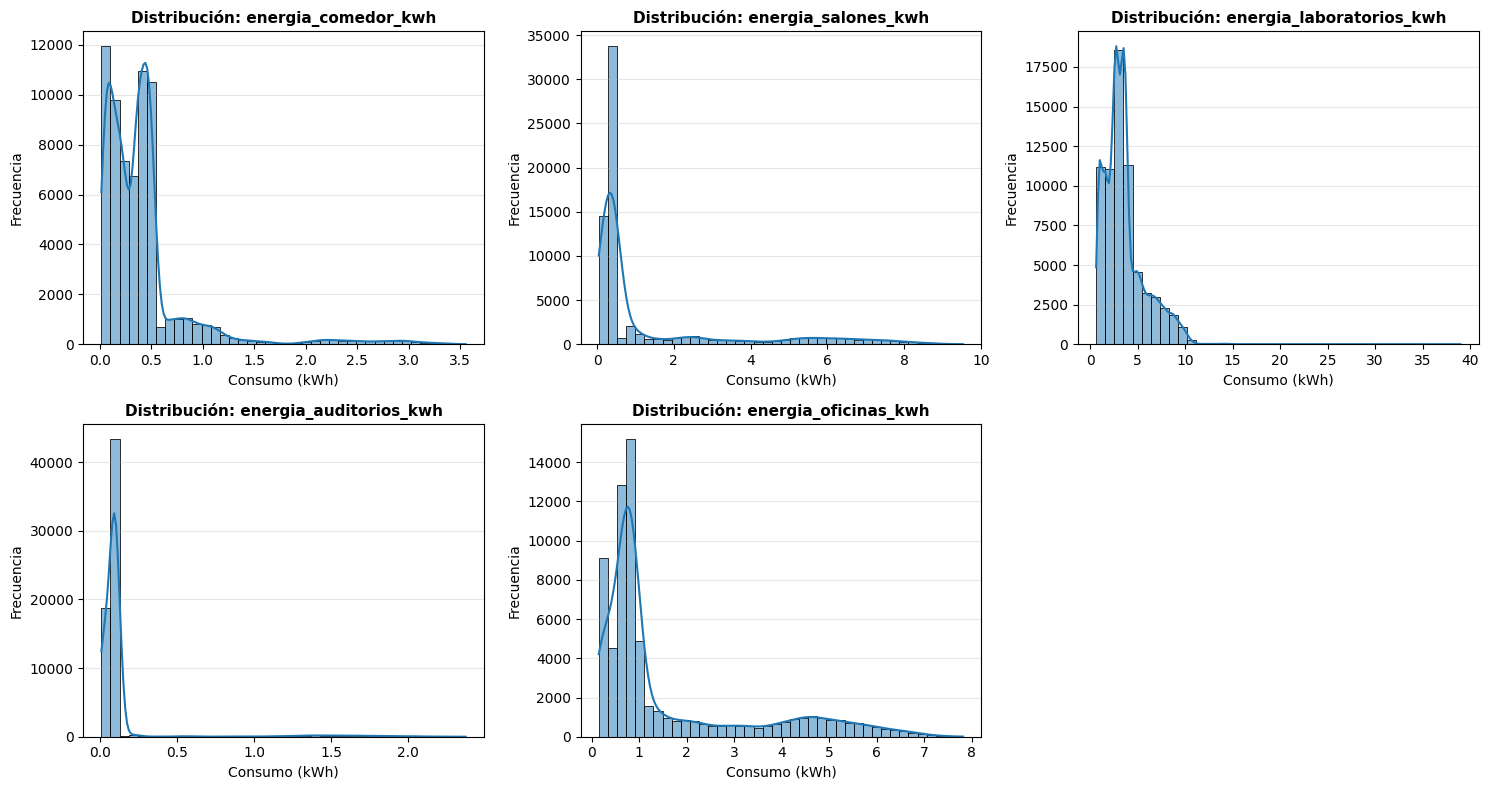

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

vars_energia = [
    'energia_comedor_kwh',
    'energia_salones_kwh',
    'energia_laboratorios_kwh',
    'energia_auditorios_kwh',
    'energia_oficinas_kwh'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(vars_energia):
    sns.histplot(df_duitama_limpio[col].dropna(), bins=40, kde=True, ax=axes[i], color='#1f77b4')
    axes[i].set_title(f'Distribución: {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Consumo (kWh)')
    axes[i].set_ylabel('Frecuencia')
    axes[i].grid(axis='y', alpha=0.3)

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()


>Los cinco histogramas muestran distribuciones con fuerte sesgo positivo (asimetría hacia la derecha), evidenciando un contraste marcado entre el consumo basal en reposo y los picos operativos de la jornada académica en Duitama:

>>• Patrón bimodal (reposo vs. actividad): energia_comedor_kwh (dos picos claros cerca de 0.1 y 0.45 kWh) y energia_oficinas_kwh (pico principal bajo 1 kWh y un segundo abultamiento entre 4 y 5.5 kWh) reflejan claramente la diferencia entre horarios nocturnos/fines de semana y el horario laboral activo.  
>• Alta concentración basal con colas largas: energia_salones_kwh y energia_auditorios_kwh concentran casi toda su frecuencia cerca de cero (por debajo de 0.5 kWh y 0.15 kWh, respectivamente), extendiéndose en colas muy bajas solo durante clases o eventos puntuales.  
>• Mayor carga y outliers extremos: energia_laboratorios_kwh presenta el mayor volumen de consumo normal (concentrado entre 1 y 10 kWh), pero exhibe una cola invisible que estira el eje hasta casi 40 kWh, confirmando la presencia de valores atípicos extremos.

#16. Imputar valores nulos:
* Mediana para variables numéricas.
* Moda para variables categóricas

In [ ]:
cols_numericas = df_duitama_limpio.select_dtypes(include=['number']).columns
cols_categoricas = df_duitama_limpio.select_dtypes(include=['object', 'category', 'bool']).columns

for col in cols_numericas:
    if df_duitama_limpio[col].isnull().sum() > 0:
        mediana = df_duitama_limpio[col].median()
        df_duitama_limpio[col] = df_duitama_limpio[col].fillna(mediana)

for col in cols_categoricas:
    if df_duitama_limpio[col].isnull().sum() > 0:
        moda = df_duitama_limpio[col].mode()[0]
        df_duitama_limpio[col] = df_duitama_limpio[col].fillna(moda)

print("Total de valores nulos restantes:", df_duitama_limpio.isnull().sum().sum())


Total de valores nulos restantes: 0


>La imputación fue exitosa y dejó el dataset de Duitama 100% completo (0 valores nulos en las 68,487 filas y 26 columnas). Al rellenar las variables numéricas incompletas (energia_comedor_kwh, energia_auditorios_kwh, agua_litros, temperatura_exterior_c, ocupacion_pct y co2_kg) con la mediana, se preservaron las distribuciones originales sin sesgarlas por los outliers extremos detectados en los histogramas, dejando el conjunto de datos totalmente listo para el análisis exploratorio o el modelado.

#17. Construir e interpretar la matriz de correlación

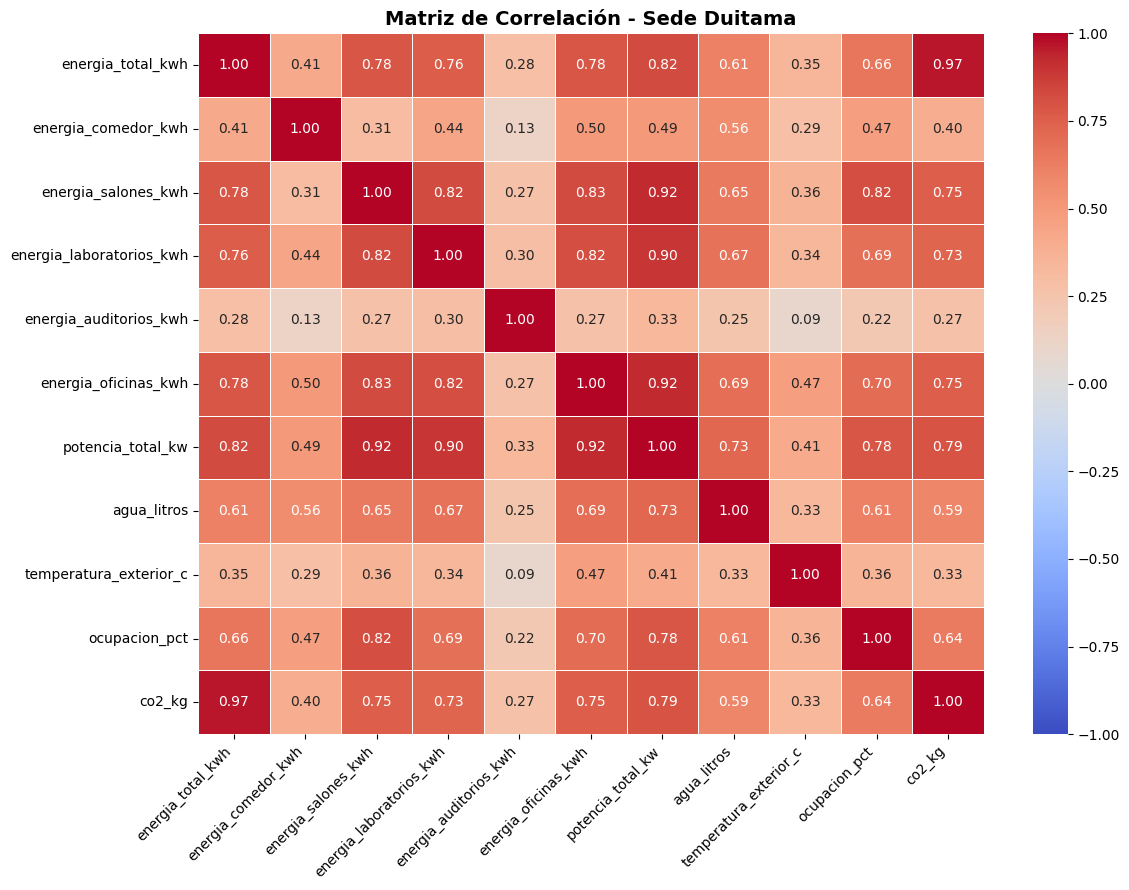

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

vars_corr = [
    'energia_total_kwh', 'energia_comedor_kwh', 'energia_salones_kwh',
    'energia_laboratorios_kwh', 'energia_auditorios_kwh', 'energia_oficinas_kwh',
    'potencia_total_kw', 'agua_litros', 'temperatura_exterior_c',
    'ocupacion_pct', 'co2_kg'
]


matriz_corr = df_duitama_limpio[vars_corr].corr()


plt.figure(figsize=(12, 9))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlación - Sede Duitama', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


>La matriz de correlación de Duitama demuestra que la actividad humana (ocupación) es el motor principal del consumo energético e hídrico del campus, mientras que el clima tiene un impacto marginal:  
>>• Variables derivadas (alta redundancia): energia_total_kwh se correlaciona al 0.97 con co2_kg y al 0.82 con potencia_total_kw (debes excluir estas dos si vas a predecir la energía total para evitar fuga de datos).  
• Núcleo de consumo académico: Salones, oficinas y laboratorios operan sincronizados (0.82 – 0.83) y son los que más impulsan la energía total (0.76 – 0.78).  
• Impacto de la ocupación: ocupacion_pct explica gran parte del gasto en salones (0.82), oficinas (0.70) y agua (0.61).  
• Baja dependencia: energia_auditorios_kwh (≤ 0.33) y temperatura_exterior_c (≤ 0.47) tienen poca relación con el resto del sistema, reflejando eventos aislados y la baja necesidad de climatización artificial en el clima frío de Duitama.

#Fase IV. Preparación para modelado

#18. Seleccionar las variables objetivo.

In [ ]:
y = df_duitama_limpio['energia_total_kwh']

features = [
    'temperatura_exterior_c', 'ocupacion_pct', 'hora', 'dia_semana',
    'mes', 'trimestre', 'periodo_academico', 'es_fin_semana',
    'es_festivo', 'es_semana_parciales', 'es_semana_finales'
]

X = df_duitama_limpio[features]

print("Dimensiones de X (predictoras):", X.shape)
print("Dimensiones de y (objetivo):", y.shape)


Dimensiones de X (predictoras): (68487, 11)
Dimensiones de y (objetivo): (68487,)
